In [1]:
from lakehouse_spark import SparkSessionContext
from pyspark.sql import functions as F


with SparkSessionContext('example-context-properties') as spark:
    print(spark.version)
    print(spark.sparkContext.applicationId)
    print(spark.sparkContext.master)
    print(spark.conf.get("spark.sql.shuffle.partitions"))


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/14 13:30:05 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


4.1.2
app-20261114133007-1933
spark://spark-master:7077
4


In [ ]:
from lakehouse_spark import SparkSessionContext
from pyspark.sql import functions as F
with SparkSessionContext('create-schemas') as spark:
    spark.sql("CREATE SCHEMA IF NOT EXISTS lakehouse.stage")
    spark.sql("CREATE SCHEMA IF NOT EXISTS lakehouse.mart")
    print("Схемы stage и mart созданы!")

In [1]:
with SparkSessionContext('build-stage-layer-clean') as spark:
    # 1. Матчи
    spark.sql("""
        CREATE OR REPLACE TABLE lakehouse.stage.matches USING iceberg AS
        SELECT match_id, duration FROM lakehouse.raw.pg__matches
        WHERE duration >= 900 AND lobby_type = 7
    """)
    # 2. Игроки
    spark.sql("""
        CREATE OR REPLACE TABLE lakehouse.stage.players USING iceberg AS
        SELECT match_id, player_slot, account_id, hero_id, kills, deaths, assists, 
               gold_per_min, xp_per_min, last_hits, denies, net_worth
        FROM lakehouse.raw.pg__match_players WHERE account_id IS NOT NULL
    """)
    # 3. Варды
    spark.sql("""
        CREATE OR REPLACE TABLE lakehouse.stage.wards USING iceberg AS
        SELECT match_id, fromPlayer AS account_id,
               SUM(CASE WHEN action = 'SPAWN' THEN 1 ELSE 0 END) AS wards_placed,
               SUM(CASE WHEN action = 'DESPAWN' AND playerDestroyed = fromPlayer THEN 1 ELSE 0 END) AS wards_destroyed
        FROM lakehouse.raw.mongo__ward_events GROUP BY match_id, fromPlayer
    """)
    # 4. Крипы
    spark.sql("""
        CREATE OR REPLACE TABLE lakehouse.stage.cs USING iceberg AS
        SELECT match_id, steam_account_id AS account_id, SUM(gold) AS gold_from_cs, COUNT(*) AS total_cs
        FROM lakehouse.raw.mongo__cs_events WHERE isFromIllusion = false GROUP BY match_id, steam_account_id
    """)
    # 5. Предметы
    spark.sql("""
        CREATE OR REPLACE TABLE lakehouse.stage.items USING iceberg AS
        SELECT match_id, steam_account_id AS account_id,
               SUM(CASE WHEN time < 900 THEN 1 ELSE 0 END) AS items_s1,
               SUM(CASE WHEN time >= 900 AND time < 1800 THEN 1 ELSE 0 END) AS items_s2,
               SUM(CASE WHEN time >= 1800 THEN 1 ELSE 0 END) AS items_s3
        FROM lakehouse.raw.mongo__purchase_events GROUP BY match_id, steam_account_id
    """)
    # 6. Способности
    spark.sql("""
        CREATE OR REPLACE TABLE lakehouse.stage.abilities USING iceberg AS
        SELECT match_id, steam_account_id AS account_id,
               SUM(CASE WHEN time < 900 THEN 1 ELSE 0 END) AS abilities_s1,
               SUM(CASE WHEN time >= 900 AND time < 1800 THEN 1 ELSE 0 END) AS abilities_s2,
               SUM(CASE WHEN time >= 1800 THEN 1 ELSE 0 END) AS abilities_s3
        FROM lakehouse.raw.mongo__ability_learn_events WHERE isTalent = false GROUP BY match_id, steam_account_id
    """)
    # 7. Таланты
    spark.sql("""
        CREATE OR REPLACE TABLE lakehouse.stage.talents USING iceberg AS
        SELECT match_id, steam_account_id AS account_id,
               SUM(CASE WHEN time < 900 THEN 1 ELSE 0 END) AS talents_s1,
               SUM(CASE WHEN time >= 900 AND time < 1800 THEN 1 ELSE 0 END) AS talents_s2,
               SUM(CASE WHEN time >= 1800 THEN 1 ELSE 0 END) AS talents_s3
        FROM lakehouse.raw.mongo__ability_learn_events WHERE isTalent = true GROUP BY match_id, steam_account_id
    """)
    # 8. Убийства
    spark.sql("""
        CREATE OR REPLACE TABLE lakehouse.stage.kills USING iceberg AS
        SELECT match_id, steam_account_id AS account_id,
               SUM(CASE WHEN time < 900 THEN 1 ELSE 0 END) AS kills_s1,
               SUM(CASE WHEN time >= 900 AND time < 1800 THEN 1 ELSE 0 END) AS kills_s2,
               SUM(CASE WHEN time >= 1800 THEN 1 ELSE 0 END) AS kills_s3,
               SUM(CASE WHEN isSmoke THEN 1 ELSE 0 END) AS smoke_kills
        FROM lakehouse.raw.mongo__kill_events GROUP BY match_id, steam_account_id
    """)
    # 9. Смерти
    spark.sql("""
        CREATE OR REPLACE TABLE lakehouse.stage.deaths USING iceberg AS
        SELECT match_id, steam_account_id AS account_id,
               SUM(CASE WHEN time < 900 THEN 1 ELSE 0 END) AS deaths_s1,
               SUM(CASE WHEN time >= 900 AND time < 1800 THEN 1 ELSE 0 END) AS deaths_s2,
               SUM(CASE WHEN time >= 1800 THEN 1 ELSE 0 END) AS deaths_s3,
               SUM(timeDead) AS total_time_dead
        FROM lakehouse.raw.mongo__death_events GROUP BY match_id, steam_account_id
    """)
    print("Stage-слой успешно пересобран в lakehouse.stage!")

NameError: name 'SparkSessionContext' is not defined

In [12]:
with SparkSessionContext('build-mart-layer-clean') as spark:
    spark.sql("""
        CREATE OR REPLACE TABLE lakehouse.mart.match_player_features USING iceberg AS
        WITH 
        history AS (
            SELECT account_id, AVG(gold_per_min) AS avg_gpm
            FROM lakehouse.stage.players
            GROUP BY account_id
        )
        SELECT 
            p.match_id, p.player_slot, p.account_id, p.hero_id,
            p.kills, p.deaths, p.assists, 
            p.gold_per_min AS gpm, p.xp_per_min AS xpm, 
            p.last_hits, p.denies, p.net_worth,
            COALESCE(w.wards_placed, 0) AS wards_placed,
            COALESCE(w.wards_destroyed, 0) AS wards_destroyed,
            COALESCE(c.total_cs, 0) AS total_cs,
            COALESCE(c.gold_from_cs, 0) AS gold_from_cs,
            COALESCE(d.total_time_dead, 0) AS total_time_dead,
            COALESCE(k.smoke_kills, 0) AS smoke_kills,
            COALESCE(i.items_s1, 0) AS items_s1,
            COALESCE(i.items_s2, 0) AS items_s2,
            COALESCE(i.items_s3, 0) AS items_s3,
            COALESCE(a.abilities_s1, 0) AS abilities_s1,
            COALESCE(a.abilities_s2, 0) AS abilities_s2,
            COALESCE(a.abilities_s3, 0) AS abilities_s3,
            COALESCE(t.talents_s1, 0) AS talents_s1,
            COALESCE(t.talents_s2, 0) AS talents_s2,
            COALESCE(t.talents_s3, 0) AS talents_s3,
            COALESCE(k.kills_s1, 0) AS kills_s1,
            COALESCE(k.kills_s2, 0) AS kills_s2,
            COALESCE(k.kills_s3, 0) AS kills_s3,
            COALESCE(d.deaths_s1, 0) AS deaths_s1,
            COALESCE(d.deaths_s2, 0) AS deaths_s2,
            COALESCE(d.deaths_s3, 0) AS deaths_s3,
            COALESCE(h.avg_gpm, 0) AS player_avg_gpm,
            CASE WHEN h.avg_gpm > 0 THEN p.gold_per_min / h.avg_gpm ELSE 1.0 END AS gpm_ratio_to_avg
        FROM lakehouse.stage.players p
        JOIN lakehouse.stage.matches m ON p.match_id = m.match_id
        LEFT JOIN lakehouse.stage.wards w ON p.match_id = w.match_id AND p.account_id = w.account_id
        LEFT JOIN lakehouse.stage.cs c ON p.match_id = c.match_id AND p.account_id = c.account_id
        LEFT JOIN lakehouse.stage.items i ON p.match_id = i.match_id AND p.account_id = i.account_id
        LEFT JOIN lakehouse.stage.abilities a ON p.match_id = a.match_id AND p.account_id = a.account_id
        LEFT JOIN lakehouse.stage.talents t ON p.match_id = t.match_id AND p.account_id = t.account_id
        LEFT JOIN lakehouse.stage.kills k ON p.match_id = k.match_id AND p.account_id = k.account_id
        LEFT JOIN lakehouse.stage.deaths d ON p.match_id = d.match_id AND p.account_id = d.account_id
        LEFT JOIN history h ON p.account_id = h.account_id
    """)
    print("Mart-слой успешно собран в lakehouse.mart!")

Mart-слой успешно собран в lakehouse.mart!


In [3]:
def find_isnull(df, cols=None):
    if cols is None:
        cols = df.columns
    n = 0
    print("--- ДИАГНОСТИКА ПРОПУСКОВ ---")
    for col in cols:
        # Защита от текстовых колонок: isnan работает только с числами
        cond = F.col(col).isNull()
        if dict(df.dtypes)[col] in ("double", "float", "int", "bigint"):
            cond = cond | F.isnan(F.col(col))
            
        num_isna = df.filter(cond).count()
        print(f"Пропуски в {col:<20}: {num_isna}")
        n += num_isna
    print(f"Всего пропусков: {n}\n")

def fill_nulls(df, feature_cols):
    print("--- ЗАПОЛНЕНИЕ ПРОПУСКОВ ---")
    for c in feature_cols:
        df = df.withColumn(# работаем с копией таблицы
            c,
            F.when(# условия
                F.col(c).isNull() 
                | F.isnan(F.col(c).cast("double")) 
                | (F.col(c) == float("inf")) 
                | (F.col(c) == float("-inf")),
                F.lit(0.0) # замена на значение
            ).otherwise(F.col(c).cast("double")) # cast - сммена типа данных
        )
    print("Пропуски и Infinity заменены на 0.0\n")
    return df

def clip_outliers_iqr(df, cols=None, threshold=0.08):
    if cols is None:
        numeric_types = ("int", "bigint", "double", "float", "smallint")
        cols = [c for c, t in df.dtypes if t in numeric_types]
    
    total = df.count()
    if total == 0: return df
    
    result = df
    print("--- ОБРЕЗКА ВЫБРОСОВ (CLIPPING) ---")
    for col in cols:
        q1, q3 = result.approxQuantile(col, [0.25, 0.75], 0.01)
        iqr = q3 - q1
        
        if iqr == 0:
            print(f"[{col}] IQR=0 → пропускаем")
            continue
        
        lower, upper = round(q1 - 1.5 * iqr, 4), round(q3 + 1.5 * iqr, 4)
        outliers_count = result.filter((F.col(col) < lower) | (F.col(col) > upper)).count()
        percent = outliers_count / total
        
        if percent > threshold:
            print(f"[{col}] {percent:.1%} выбросов → пропускаем (это норма)")
        else:
            result = result.withColumn(
                col,
                F.least(F.greatest(F.col(col).cast("double"), F.lit(lower)), F.lit(upper))
            )
            print(f"[{col}] Зажато в [{lower}, {upper}] (было {percent:.1%} выбросов)")
    print("\n")
    return result

In [4]:
with SparkSessionContext('clean-data-pipeline') as spark:
    # 1. Загружаем витрину
    print("1. Загрузка данных...")
    df = spark.table("lakehouse.mart.match_player_features")
    
    # Список фич, которые идут в модель
    feature_cols = [
        "kills", "deaths", "assists",
        "gpm", "xpm",
        "wards_placed", "wards_destroyed",
        "total_cs",
        "items_s1", "items_s2", "items_s3",
        "gpm_ratio_to_avg"
    ]
    
    # Оставляем только нужные колонки (чтобы не тащить лишнее)
    df = df.select("match_id", "player_slot", *feature_cols)

    # 2. Смотрим исходные пропуски
    find_isnull(df, feature_cols)

    # 3. Заполняем NULL/NaN/Inf на 0.0
    df_clean = fill_nulls(df, feature_cols)

    # 4. Зажимаем выбросы (те, что не являются "особенностью данных")
    df_clean = clip_outliers_iqr(df_clean, feature_cols, threshold=0.08)

    # 5. Проверяем, что пропусков больше не осталось
    find_isnull(df_clean, feature_cols)

    # 6. Сохраняем очищенную таблицу!
    print("7. Сохранение очищенных данных...")
    df_clean.writeTo("lakehouse.mart.match_player_features_cleaned").createOrReplace()
    
    print("✅ Готово! Данные очищены и сохранены в lakehouse.mart.match_player_features_cleaned")

1. Загрузка данных...
--- ДИАГНОСТИКА ПРОПУСКОВ ---


Пропуски в kills               : 0
Пропуски в deaths              : 0
Пропуски в assists             : 0
Пропуски в gpm                 : 0
Пропуски в xpm                 : 0
Пропуски в wards_placed        : 0
Пропуски в wards_destroyed     : 0
Пропуски в total_cs            : 0
Пропуски в items_s1            : 0
Пропуски в items_s2            : 0
Пропуски в items_s3            : 0
Пропуски в gpm_ratio_to_avg    : 0
Всего пропусков: 0

--- ЗАПОЛНЕНИЕ ПРОПУСКОВ ---
Пропуски и Infinity заменены на 0.0

--- ОБРЕЗКА ВЫБРОСОВ (CLIPPING) ---


[kills] Зажато в [-6.5, 21.5] (было 2.8% выбросов)


[deaths] Зажато в [-4.0, 20.0] (было 0.4% выбросов)
[assists] Зажато в [-9.0, 39.0] (было 0.5% выбросов)
[gpm] Зажато в [17.5, 925.5] (было 0.5% выбросов)


[xpm] Зажато в [24.5, 1332.5] (было 1.0% выбросов)
[wards_placed] IQR=0 → пропускаем
[wards_destroyed] IQR=0 → пропускаем


[total_cs] Зажато в [-284.5, 559.5] (было 1.4% выбросов)
[items_s1] Зажато в [-8.0, 32.0] (было 0.8% выбросов)
[items_s2] Зажато в [-10.0, 22.0] (было 3.0% выбросов)
[items_s3] Зажато в [-10.5, 17.5] (было 5.8% выбросов)


[gpm_ratio_to_avg] Зажато в [0.4484, 1.4015] (было 4.3% выбросов)


--- ДИАГНОСТИКА ПРОПУСКОВ ---
Пропуски в kills               : 0
Пропуски в deaths              : 0
Пропуски в assists             : 0
Пропуски в gpm                 : 0
Пропуски в xpm                 : 0
Пропуски в wards_placed        : 0
Пропуски в wards_destroyed     : 0
Пропуски в total_cs            : 0
Пропуски в items_s1            : 0
Пропуски в items_s2            : 0
Пропуски в items_s3            : 0
Пропуски в gpm_ratio_to_avg    : 0
Всего пропусков: 0

7. Сохранение очищенных данных...


✅ Готово! Данные очищены и сохранены в lakehouse.mart.match_player_features_cleaned


In [4]:
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.clustering import KMeans
from pyspark.ml.linalg import DenseVector, VectorUDT
from pyspark.sql.types import DoubleType

# Обертка для конвертации SparseVector в DenseVector (лечит ArrayIndexOutOfBounds)
to_dense = F.udf(lambda v: DenseVector(v.toArray()) if v is not None else None, VectorUDT())


# в итоге получает датафрейм с match_id, roles (кластеры)
with SparkSessionContext('kmeans-robust') as spark:
    print("1. Загрузка данных...")
    df = spark.table("lakehouse.mart.match_player_features_cleaned")

    df = df.repartition(32).cache()
    print(f"Партиций: {df.rdd.getNumPartitions()}")
    df.count()  # триггерим кеш

    feature_cols = [
        "kills", "deaths", "assists",
        "gpm", "xpm",
        "wards_placed", "wards_destroyed",
        "total_cs",
        "items_s1", "items_s2", "items_s3",
        "gpm_ratio_to_avg"   
    ]

    # ШАГ 3: Удаление колонок с нулевой дисперсией (лечит ошибки масштабирования)
    print("4. Поиск активных признаков...")
    stats = df.select([
        F.stddev(F.col(c)).alias(c) for c in feature_cols
    ]).first()
    
    active_features = [c for c in feature_cols if stats[c] is not None and stats[c] > 1e-6]
    dropped = set(feature_cols) - set(active_features)
    if dropped:
        print(f"   ВНИМАНИЕ: Удалены колонки с нулевой дисперсией: {dropped}")
    
    if len(active_features) == 0:
        raise ValueError("Все признаки имеют нулевую дисперсию. Проверьте данные.")

    # ШАГ 4: Сборка вектора
    print("5. Сборка вектора...")
    assembler = VectorAssembler(
        inputCols=active_features,
        outputCol="raw_features",
        handleInvalid="skip"
    )
    df_vec = assembler.transform(df)

    # ШАГ 5: Превращение SparseVector в DenseVector
    print("6. Конвертация в DenseVector...")
    df_vec = df_vec.withColumn("raw_features", to_dense(F.col("raw_features")))
    df_vec = df_vec.filter(F.col("raw_features").isNotNull())

    # ШАГ 6: Масштабирование
    print("7. Масштабирование (StandardScaler)...")
    scaler = StandardScaler(
        inputCol="raw_features",
        outputCol="features",
        withMean=True,
        withStd=True
    )
    scaler_model = scaler.fit(df_vec)
    df_scaled = scaler_model.transform(df_vec)

    # Финальная проверка на NaN в векторе
    def has_bad(v):
        return any(x != x or x == float("inf") or x == float("-inf") for x in v.toArray())
    
    has_bad_udf = F.udf(has_bad, "boolean")
    df_scaled = df_scaled.filter(~has_bad_udf("features"))

    # ШАГ 7: Проверка на количество уникальных строк
    total_rows = df_scaled.count()
    unique_vectors = df_scaled.select("features").distinct().count()
    print(f"8. Итого строк: {total_rows}, уникальных векторов: {unique_vectors}")

    k = 5
    if unique_vectors < k:
        raise ValueError(f"ОШИБКА: Уникальных векторов ({unique_vectors}) меньше, чем кластеров ({k}).")

    # ШАГ 8: Обучение
    print(f"9. Обучение K-Means (k={k}, initMode='random')...")
    kmeans = KMeans(
        k=k,
        seed=42,
        featuresCol="features",
        predictionCol="cluster",
        maxIter=50,
        tol=1e-4,
        initMode="random"
    )
    
    model = kmeans.fit(df_scaled)
    print("✅ Модель успешно обучена!")

    # ШАГ 9: Сохранение модели и вывод результатов
    model_path = "lakehouse.mart/models/kmeans_roles"
    model.write().overwrite().save(model_path)
    print(f"10. Модель сохранена в {model_path}")

    print("\n--- СТАТИСТИКА МАСШТАБИРОВАНИЯ ---")
    print("STD:", scaler_model.std.toArray())
    print("MEAN:", scaler_model.mean.toArray())

    print("\n--- РАЗМЕРЫ КЛАСТЕРОВ ---")
    # Сохраняем предсказания в переменную, чтобы использовать её дальше
    predictions = model.transform(df_scaled)
    predictions.groupBy("cluster").count().orderBy("cluster").show()

    # ШАГ 10 (НОВЫЙ): ПРИСВОЕНИЕ И СОХРАНЕНИЕ МЕТОК

    print("11. Сохранение меток (role_position) в отдельную таблицу...")
    
    # Оставляем только ключи и переименовываем cluster в role_position
    labels = predictions.select(
        "match_id", 
        "player_slot", 
        F.col("cluster").alias("role_position")
    )
    
    # Сохраняем в Iceberg
    labels.writeTo("lakehouse.mart.role_labels").createOrReplace()
    
    print("✅ Метки успешно сохранены в lakehouse.mart.role_labels!")
    
    # Проверка сохраненных данных
    spark.table("lakehouse.mart.role_labels").show(5)

1. Загрузка данных...


[Stage 2:=====================================================>   (30 + 1) / 32]

Партиций: 32


4. Поиск активных признаков...


   ВНИМАНИЕ: Удалены колонки с нулевой дисперсией: {'wards_placed', 'wards_destroyed'}
5. Сборка вектора...
6. Конвертация в DenseVector...
7. Масштабирование (StandardScaler)...


8. Итого строк: 1765590, уникальных векторов: 1765213
9. Обучение K-Means (k=5, initMode='random')...


✅ Модель успешно обучена!


10. Модель сохранена в lakehouse.mart/models/kmeans_roles

--- СТАТИСТИКА МАСШТАБИРОВАНИЯ ---
STD: [5.33369264e+00 4.12361056e+00 8.10305820e+00 1.56498615e+02
 2.40888307e+02 1.42479703e+02 8.07258347e+00 6.17690988e+00
 5.27149333e+00 2.15432012e-01]
MEAN: [  7.99157081   8.28622047  15.12278898 478.1965091  689.97530995
 153.40988848  11.92513381   6.85728963   4.1584258    0.93368315]

--- РАЗМЕРЫ КЛАСТЕРОВ ---


+-------+------+
|cluster| count|
+-------+------+
|      0|299231|
|      1|458593|
|      2|359556|
|      3|324624|
|      4|323586|
+-------+------+

11. Сохранение меток (role_position) в отдельную таблицу...


✅ Метки успешно сохранены в lakehouse.mart.role_labels!
+----------+-----------+-------------+
|  match_id|player_slot|role_position|
+----------+-----------+-------------+
|9044936805|        128|            1|
|9045103500|        128|            3|
|9044936748|        131|            4|
|9044917269|        128|            1|
|9045227545|          0|            1|
+----------+-----------+-------------+
only showing top 5 rows


In [11]:
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from pyspark.ml.functions import vector_to_array
from pyspark.sql import functions as F

with SparkSessionContext('rf-training') as spark:
    print("1. Загрузка данных...")
    df = spark.table("lakehouse.mart.match_player_features_cleaned").repartition(32).cache()
    print(f"   Партиций: {df.rdd.getNumPartitions()}")
    df.count()  # триггерим кеш
    
    labels = spark.table("lakehouse.mart.role_labels")
    data = df.join(labels, on=["match_id", "player_slot"], how="inner") \
             .withColumnRenamed("role_position", "label")
    print(f"   Строк после JOIN: {data.count()}")
    
    feature_cols = [
        "kills", "deaths", "assists", "gpm", "xpm",
        "wards_placed", "wards_destroyed", "total_cs",
        "items_s1", "items_s2", "items_s3", "gpm_ratio_to_avg"
    ]
    
    assembler = VectorAssembler(inputCols=feature_cols, outputCol="features", handleInvalid="skip")
    data = assembler.transform(data).filter(F.col("features").isNotNull())
    
    # Split по match_id
    train_ids, test_ids = data.select("match_id").distinct().randomSplit([0.8, 0.2], seed=42)
    train = data.join(train_ids, on="match_id").repartition(32).cache()
    test  = data.join(test_ids,  on="match_id").repartition(32).cache()
    print(f"   Train: {train.count()}, Test: {test.count()}")
    

    # 2. Обучение Random Forest (средние параметры, без сетки)

    print("\n2. Обучение Random Forest...")
    rf = RandomForestClassifier(
        featuresCol="features",
        labelCol="label",
        numTrees=100,                  # среднее значение: 100 деревьев
        maxDepth=8,                    # средняя глубина
        minInstancesPerNode=5,         # среднее
        featureSubsetStrategy="sqrt",  # стандарт для классификации
        seed=42
    )
    
    model = rf.fit(train)
    print("✅ Модель обучена!")
    
    # Оценка на тесте
    final_preds = model.transform(test)
    evaluator = MulticlassClassificationEvaluator(
        labelCol="label", predictionCol="prediction", metricName="f1"
    )
    f1 = evaluator.evaluate(final_preds)
    print(f"   F1 на тесте: {f1:.4f}")
    

    # 3. Сохранение модели

    model.write().overwrite().save("lakehouse.mart/models/rf_roles_best")
    print("✅ Модель сохранена в lakehouse.mart/models/rf_roles_best")
    

    # 4. Сохранение важности признаков (обход бага load() из Iceberg)
    
    imp_data = [(f, float(i)) for f, i in zip(feature_cols, model.featureImportances.toArray())]
    spark.createDataFrame(imp_data, ["feature", "importance"]) \
        .writeTo("lakehouse.mart.rf_feature_importance") \
        .createOrReplace()
    print("✅ Feature importance сохранена в lakehouse.mart.rf_feature_importance")
    

    # 5. Сохранение предсказаний на тесте

    final_preds.select(
        "match_id", "player_slot", "label", "prediction",
        vector_to_array("probability").alias("probability_array")
    ).writeTo("lakehouse.mart.rf_test_predictions").createOrReplace()
    print("✅ Предсказания сохранены в lakehouse.mart.rf_test_predictions")

1. Загрузка данных...


[Stage 2:=======================================================> (31 + 1) / 32]

   Партиций: 32


   Строк после JOIN: 1765590


   Train: 1412340, Test: 353250

2. Обучение Random Forest...


26/11/14 18:47:24 WARN DAGScheduler: Broadcasting large task binary with size 1181.2 KiB
26/11/14 18:48:15 WARN DAGScheduler: Broadcasting large task binary with size 2.2 MiB
26/11/14 18:49:28 WARN DAGScheduler: Broadcasting large task binary with size 4.4 MiB
26/11/14 18:51:06 WARN DAGScheduler: Broadcasting large task binary with size 1342.9 KiB
                                                                                

... (4 outputs left out)

✅ Модель сохранена в lakehouse.mart/models/rf_roles_best


✅ Feature importance сохранена в lakehouse.mart.rf_feature_importance


26/11/14 18:51:32 WARN DAGScheduler: Broadcasting large task binary with size 3.3 MiB
                                                                                

✅ Предсказания сохранены в lakehouse.mart.rf_test_predictions


1. Загрузка предсказаний...


   Строк: 353250

--- МЕТРИКИ ---


  accuracy            : 0.9211


  f1                  : 0.9214


  weightedPrecision   : 0.9223


  weightedRecall      : 0.9211

--- CONFUSION MATRIX ---


+-----+----------+-----+
|label|prediction|count|
+-----+----------+-----+
|    0|       0.0|57709|
|    0|       1.0| 1226|
|    0|       2.0|  953|
|    0|       3.0|   90|
|    0|       4.0|   75|
|    1|       0.0|  524|
|    1|       1.0|84013|
|    1|       2.0| 3084|
|    1|       3.0| 2586|
|    1|       4.0| 1725|
|    2|       0.0|  111|
|    2|       1.0| 5088|
|    2|       2.0|64141|
|    2|       4.0| 2461|
|    3|       0.0|  174|
|    3|       1.0| 4565|
|    3|       3.0|59545|
|    3|       4.0|  404|
|    4|       1.0| 2172|
|    4|       2.0| 2185|
+-----+----------+-----+
only showing top 20 rows
--- PER-CLASS RECALL ---


  Класс 0: 57709/60053 = 0.9610
  Класс 1: 84013/91932 = 0.9139
  Класс 2: 64141/71801 = 0.8933


  Класс 3: 59545/64688 = 0.9205
  Класс 4: 59960/64776 = 0.9257
--- PER-CLASS PRECISION ---
  Класс 0: 57709/58518 = 0.9862
  Класс 1: 84013/97064 = 0.8655
  Класс 2: 64141/70363 = 0.9116
  Класс 3: 59545/62680 = 0.9500
  Класс 4: 59960/64625 = 0.9278

--- FEATURE IMPORTANCE ---
  gpm                      0.2108  █████████████████████
  xpm                      0.1779  █████████████████
  items_s1                 0.1220  ████████████
  items_s3                 0.1209  ████████████
  total_cs                 0.1195  ███████████
  items_s2                 0.1043  ██████████
  kills                    0.0620  ██████
  assists                  0.0396  ███
  gpm_ratio_to_avg         0.0396  ███
  deaths                   0.0035  
  wards_destroyed          0.0000  
  wards_placed             0.0000  


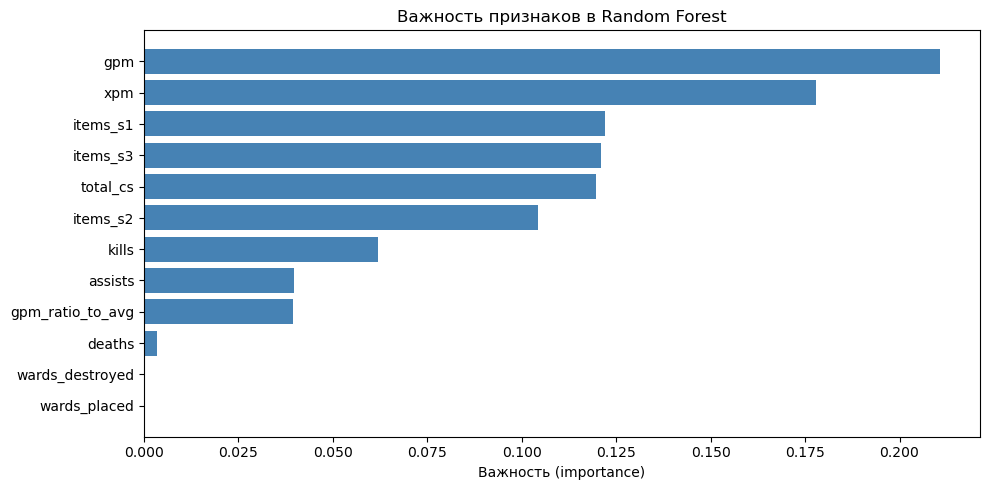


2. Строим ROC-кривые...


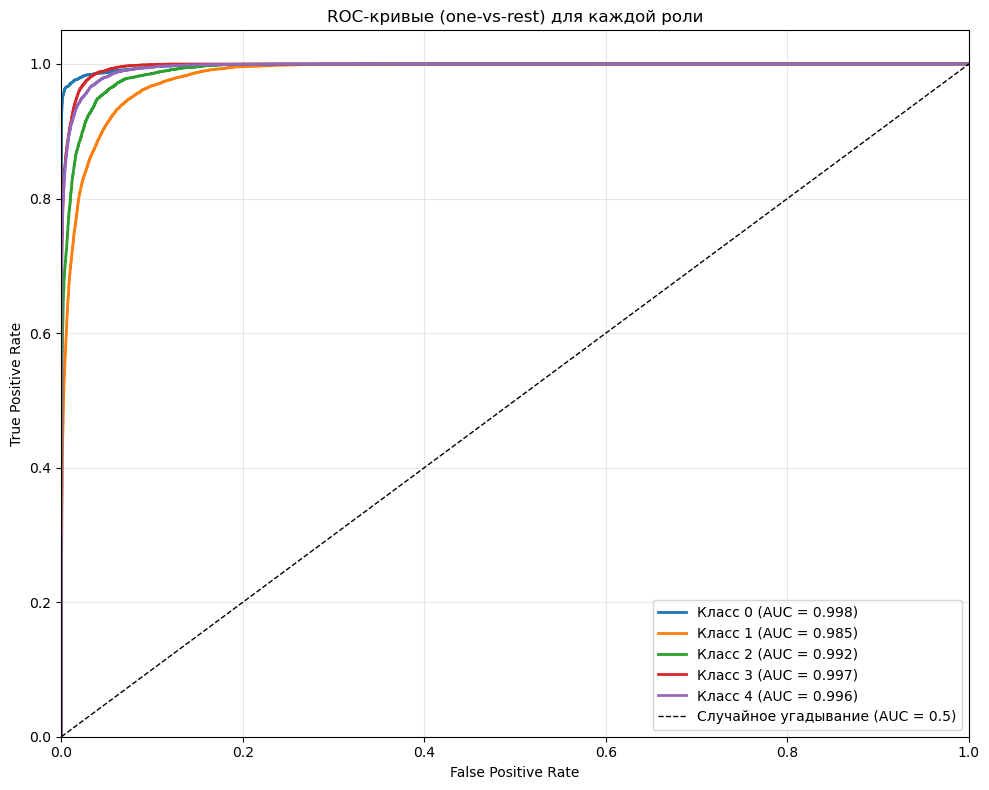


--- AUC ПО КЛАССАМ ---
  Класс 0: AUC = 0.9983 (отлично)
  Класс 1: AUC = 0.9848 (отлично)
  Класс 2: AUC = 0.9917 (отлично)
  Класс 3: AUC = 0.9971 (отлично)
  Класс 4: AUC = 0.9960 (отлично)


In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from pyspark.ml.functions import vector_to_array
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from pyspark.sql import functions as F
import numpy as np
from lakehouse_spark import SparkSessionContext

with SparkSessionContext('rf-metrics') as spark:
    print("1. Загрузка предсказаний...")
    preds = spark.table("lakehouse.mart.rf_test_predictions")
    total = preds.count()
    print(f"   Строк: {total}")
    
    # =========================================================
    # 1. ОБЩИЕ МЕТРИКИ
    # =========================================================
    print("\n--- МЕТРИКИ ---")
    for metric in ["accuracy", "f1", "weightedPrecision", "weightedRecall"]:
        val = MulticlassClassificationEvaluator(
            labelCol="label", predictionCol="prediction", metricName=metric
        ).evaluate(preds)
        print(f"  {metric:<20}: {val:.4f}")
    
    print("\n--- CONFUSION MATRIX ---")
    preds.groupBy("label", "prediction").count().orderBy("label", "prediction").show()
    
    # =========================================================
    # 2. PER-CLASS RECALL + PRECISION
    # =========================================================
    print("--- PER-CLASS RECALL ---")
    for c in range(5):
        tp = preds.filter((F.col("label") == c) & (F.col("prediction") == c)).count()
        total_c = preds.filter(F.col("label") == c).count()
        if total_c > 0:
            print(f"  Класс {c}: {tp}/{total_c} = {tp/total_c:.4f}")
    
    print("--- PER-CLASS PRECISION ---")
    for c in range(5):
        tp = preds.filter((F.col("label") == c) & (F.col("prediction") == c)).count()
        predicted_c = preds.filter(F.col("prediction") == c).count()
        if predicted_c > 0:
            print(f"  Класс {c}: {tp}/{predicted_c} = {tp/predicted_c:.4f}")
    
    # =========================================================
    # 3. ВАЖНОСТЬ ПРИЗНАКОВ (из таблицы, а не из модели)
    # =========================================================
    print("\n--- FEATURE IMPORTANCE ---")
    try:
        imp_df = spark.table("lakehouse.mart.rf_feature_importance").toPandas()
        imp_df = imp_df.sort_values("importance", ascending=False)
        
        for _, row in imp_df.iterrows():
            bar = "█" * int(row["importance"] * 100)
            print(f"  {row['feature']:<20} {row['importance']:>10.4f}  {bar}")
        
        plt.figure(figsize=(10, 5))
        plt.barh(imp_df["feature"][::-1], imp_df["importance"][::-1], color="steelblue")
        plt.xlabel("Важность (importance)")
        plt.title("Важность признаков в Random Forest")
        plt.tight_layout()
        plt.show()
    except Exception as e:
        print(f"  ⚠️ Не удалось загрузить важность: {e}")
        print("  (Убедись, что в блоке обучения сохранил таблицу rf_feature_importance)")
    
    # =========================================================
    # 4. ROC-КРИВЫЕ
    # =========================================================
    print("\n2. Строим ROC-кривые...")
    
    # Автоопределение колонки с вероятностями
    if "probability_array" in preds.columns:
        preds_arr = preds.withColumn("probs", F.col("probability_array"))
    elif "probability" in preds.columns:
        preds_arr = preds.withColumn("probs", vector_to_array("probability"))
    else:
        raise ValueError("В таблице нет колонки с вероятностями!")
    
    sample_size = min(total, 50000)
    pdf = preds_arr.select("label", "probs").limit(sample_size).toPandas()
    
    plt.figure(figsize=(10, 8))
    class_aucs = []
    for k in range(5):
        y_true = (pdf["label"] == k).astype(int).values
        y_score = np.array([p[k] for p in pdf["probs"]])
        if y_true.sum() == 0 or y_true.sum() == len(y_true):
            print(f"  Класс {k}: недостаточно данных в сэмпле, пропускаем")
            continue
        fpr, tpr, _ = roc_curve(y_true, y_score)
        roc_auc = auc(fpr, tpr)
        class_aucs.append((k, roc_auc))
        plt.plot(fpr, tpr, lw=2, label=f"Класс {k} (AUC = {roc_auc:.3f})")
    
    plt.plot([0, 1], [0, 1], "k--", lw=1, label="Случайное угадывание (AUC = 0.5)")
    plt.xlim([0.0, 1.0]); plt.ylim([0.0, 1.05])
    plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
    plt.title("ROC-кривые (one-vs-rest) для каждой роли")
    plt.legend(loc="lower right"); plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    print("\n--- AUC ПО КЛАССАМ ---")
    for k, a in class_aucs:
        quality = "отлично" if a > 0.9 else "хорошо" if a > 0.8 else "средне" if a > 0.7 else "слабо"
        print(f"  Класс {k}: AUC = {a:.4f} ({quality})")